# Exploratory Data Analysis

This notebook explores the NSL-KDD training dataset stored in `data/raw`. The analysis checks the available files, loads and labels the records, examines class balance and feature distributions, and visualizes relationships and outliers in the data.

The goal is to understand the structure and quality of the traffic records before preprocessing and training a Transformer-based intrusion detection model.

In [1]:
import os

from pathlib import Path

cwd = Path.cwd()
PROJECT_DIR = next(p for p in (cwd, *cwd.parents) if (p / "data" / "raw").is_dir())
DATA_DIR = PROJECT_DIR / "data" / "raw"
print("Dataset path:")
print(DATA_DIR)

print("\nFiles:")
for file in os.listdir(DATA_DIR):
    print(file)

Dataset path:
c:\Users\majah\OneDrive\Desktop\TRANSFORMER\data\raw

Files:
index.html
KDDTest+.arff
KDDTest+.txt
KDDTest-21.arff
KDDTest-21.txt
KDDTest1.jpg
KDDTrain+.arff
KDDTrain+.txt
KDDTrain+_20Percent.arff
KDDTrain+_20Percent.txt
KDDTrain1.jpg


## Load the Training Dataset

Import pandas and build the path to `KDDTrain+.txt`. The file is read without headers because the raw NSL-KDD text file does not include column names. The first rows provide a quick check that the records were loaded correctly.

In [2]:
import pandas as pd

train_path = os.path.join(DATA_DIR, "KDDTrain+.txt")

df = pd.read_csv(train_path, header=None)

print(df.head())

   0    1         2   3    4     5   6   7   8   9   ...    33    34    35  \
0   0  tcp  ftp_data  SF  491     0   0   0   0   0  ...  0.17  0.03  0.17   
1   0  udp     other  SF  146     0   0   0   0   0  ...  0.00  0.60  0.88   
2   0  tcp   private  S0    0     0   0   0   0   0  ...  0.10  0.05  0.00   
3   0  tcp      http  SF  232  8153   0   0   0   0  ...  1.00  0.00  0.03   
4   0  tcp      http  SF  199   420   0   0   0   0  ...  1.00  0.00  0.00   

     36    37    38    39    40       41  42  
0  0.00  0.00  0.00  0.05  0.00   normal  20  
1  0.00  0.00  0.00  0.00  0.00   normal  15  
2  0.00  1.00  1.00  0.00  0.00  neptune  19  
3  0.04  0.03  0.01  0.00  0.01   normal  21  
4  0.00  0.00  0.00  0.00  0.00   normal  21  

[5 rows x 43 columns]


## Add Feature Names

Assign the 43 NSL-KDD feature names to the dataframe, including the target `label` and the difficulty score. Naming the columns makes the later summaries and visualizations readable and easier to reference.

In [3]:
columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
    "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

df.columns = columns

print(df.head())

   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_same_srv_rate  \
0               0       0    0  ...                    0.17   
1               0       0    0  ...                    0.00   
2               0       0    0  ...                    0.10   
3               0       0    0  ...                    1.00   
4               0       0    0  ...                    1.00   

   dst_host_diff_srv_rate  dst_host_same_src_port_rate  \
0                    0.03                         0.17   
1                    0.60                         0.88   
2             

## Inspect Shape and Data Types

Review the number of records and features, then display pandas' structural summary. This reveals the dataframe dimensions, inferred data types, non-null counts, and any immediate signs of missing values.

In [4]:
print(df.shape)
print()
print(df.info())

(125973, 43)

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 

## Examine Label Frequencies

Count every attack label and the `normal` class. This is the first direct view of the multiclass target distribution and helps identify rare attack categories that may require care during model evaluation.

In [5]:
print(df["label"].value_counts())

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


## Inspect Categorical Features

Summarize the protocol types, count the distinct services, and inspect the connection flags. These categorical fields describe the network traffic at a high level and indicate how much encoding work preprocessing will need.

In [6]:
print("Protocol types:")
print(df["protocol_type"].value_counts())

print("\nServices:")
print(df["service"].nunique())

print("\nFlags:")
print(df["flag"].value_counts())

Protocol types:
protocol_type
tcp     102689
udp      14993
icmp      8291
Name: count, dtype: int64

Services:
70

Flags:
flag
SF        74945
S0        34851
REJ       11233
RSTR       2421
RSTO       1562
S1          365
SH          271
S2          127
RSTOS0      103
S3           49
OTH          46
Name: count, dtype: int64


## Summarize Numerical Features

Generate descriptive statistics for numeric columns, including counts, means, standard deviations, and percentiles. Comparing these values helps reveal scale differences and unusually wide ranges between traffic features.

In [7]:
print(df.describe())

           duration     src_bytes     dst_bytes           land  \
count  125973.00000  1.259730e+05  1.259730e+05  125973.000000   
mean      287.14465  4.556674e+04  1.977911e+04       0.000198   
std      2604.51531  5.870331e+06  4.021269e+06       0.014086   
min         0.00000  0.000000e+00  0.000000e+00       0.000000   
25%         0.00000  0.000000e+00  0.000000e+00       0.000000   
50%         0.00000  4.400000e+01  0.000000e+00       0.000000   
75%         0.00000  2.760000e+02  5.160000e+02       0.000000   
max     42908.00000  1.379964e+09  1.309937e+09       1.000000   

       wrong_fragment         urgent            hot  num_failed_logins  \
count   125973.000000  125973.000000  125973.000000      125973.000000   
mean         0.022687       0.000111       0.204409           0.001222   
std          0.253530       0.014366       2.149968           0.045239   
min          0.000000       0.000000       0.000000           0.000000   
25%          0.000000       0.00000

## Check for Duplicate Records

Count duplicated rows in the training dataframe. Duplicate records can bias the learned distribution and inflate evaluation results, so this check informs whether deduplication should be considered during data preparation.

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Measure Class Percentages

Convert the label counts into percentages so the relative contribution of each class is easier to compare. This view makes class imbalance more apparent than raw counts alone.

In [9]:
label_percent = df["label"].value_counts(normalize=True) * 100

print(label_percent)

label
normal             53.458281
neptune            32.716534
satan               2.883951
ipsweep             2.856961
portsweep           2.326689
smurf               2.100450
nmap                1.185175
back                0.758893
teardrop            0.708088
warezclient         0.706501
pod                 0.159558
guess_passwd        0.042073
buffer_overflow     0.023815
warezmaster         0.015876
land                0.014289
imap                0.008732
rootkit             0.007938
loadmodule          0.007144
ftp_write           0.006351
multihop            0.005557
phf                 0.003175
perl                0.002381
spy                 0.001588
Name: proportion, dtype: float64


## Create a Binary Target

Collapse the original multiclass labels into two groups: `normal` and `attack`. This creates the binary target used for a broad intrusion-detection task while preserving the original `label` column for detailed analysis.

In [10]:
df["binary_label"] = df["label"].apply(
    lambda x: "normal" if x == "normal" else "attack"
)

print(df["binary_label"].value_counts())

binary_label
normal    67343
attack    58630
Name: count, dtype: int64


## Visualize Normal Versus Attack Traffic

Plot the newly created binary target to compare normal records with attacks. A large difference between the bars would confirm that binary classification is imbalanced and may require stratification or class-aware metrics.

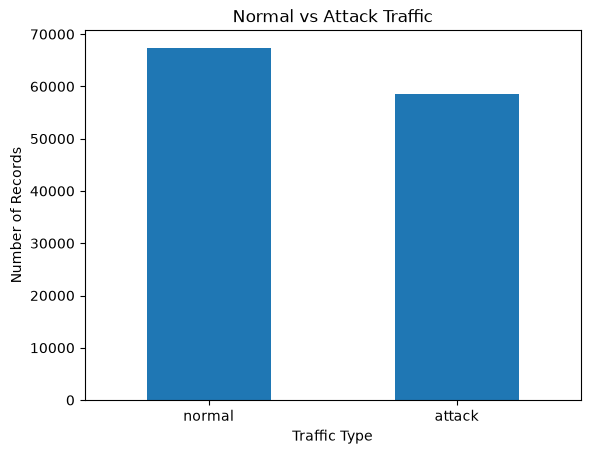

In [11]:
import matplotlib.pyplot as plt

df["binary_label"].value_counts().plot(kind="bar")

plt.title("Normal vs Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

## Plot the Original Attack Classes

Display the frequency of every original label. This chart shows which attack families dominate the training set and which classes are comparatively rare, information that is important when interpreting multiclass performance.

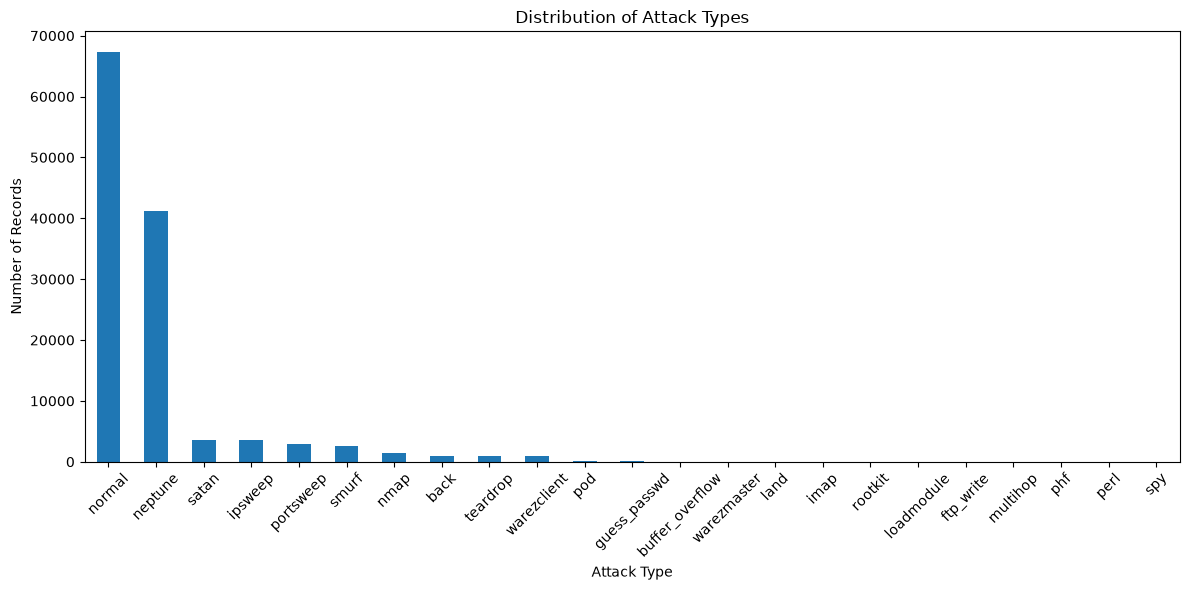

In [12]:
plt.figure(figsize=(12, 6))

df["label"].value_counts().plot(kind="bar")

plt.title("Distribution of Attack Types")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Inspect Numerical Distributions

Plot histograms for the numeric features to examine skew, concentration, and long tails. Network traffic data commonly contains heavily skewed variables, which can influence scaling and model stability.

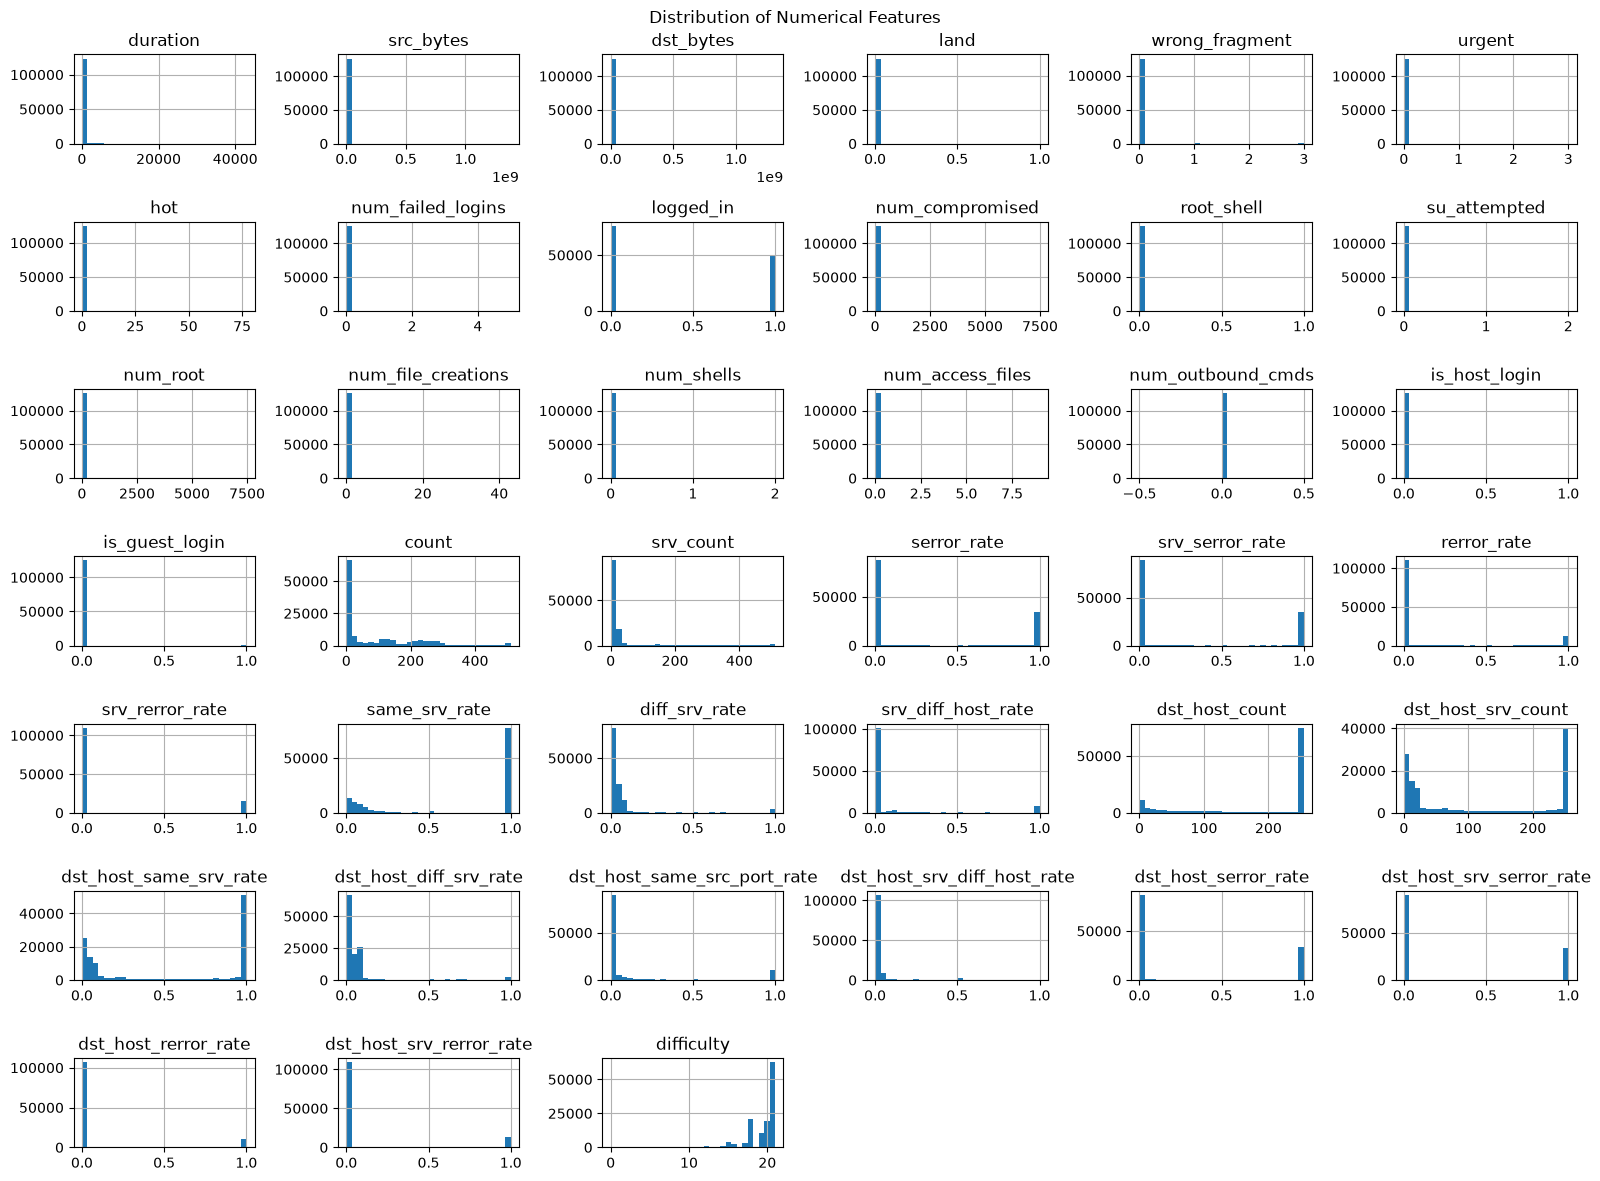

In [13]:
df.hist(figsize=(16, 12), bins=30)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

## Examine Feature Correlations

Compute correlations among numeric columns and display them as an image. Strong relationships may indicate redundant features, while weak relationships suggest that the model may need to combine many signals to separate traffic classes.

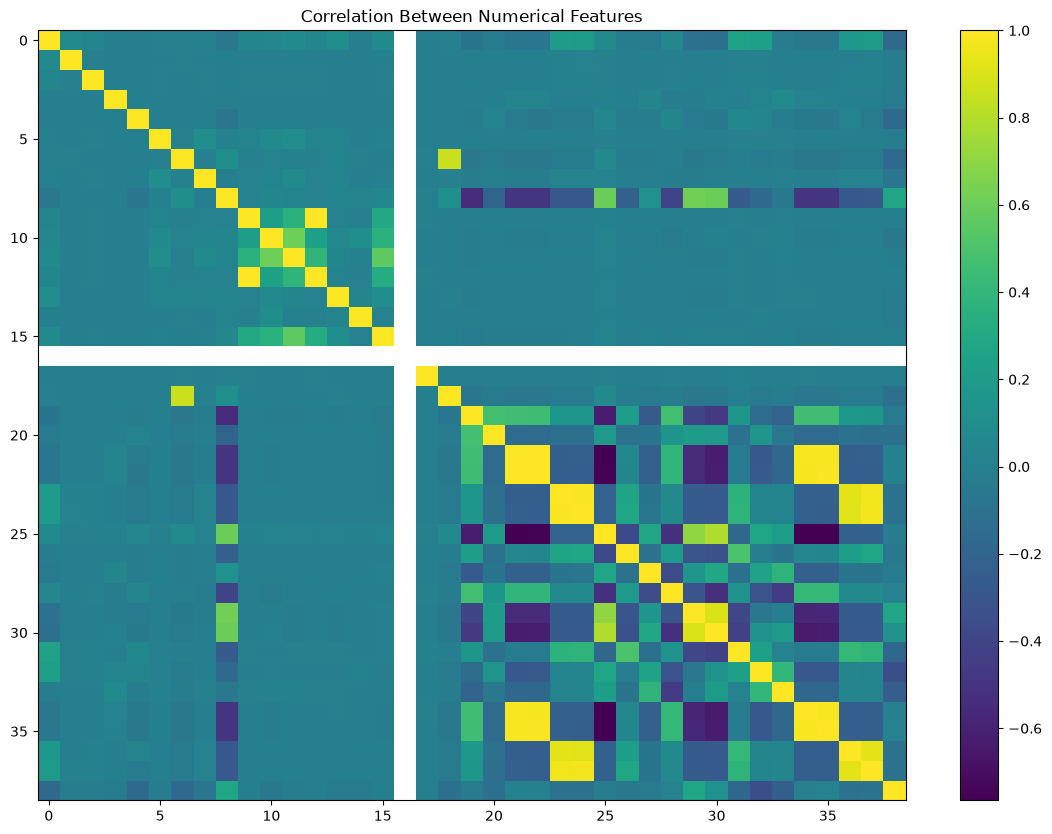

In [14]:
plt.figure(figsize=(14, 10))

corr = df.select_dtypes(include="number").corr()

plt.imshow(corr, aspect="auto")
plt.colorbar()

plt.title("Correlation Between Numerical Features")
plt.show()

## Identify Potential Outliers

Use boxplots to compare the spread and extreme values of the numeric features. Visible outliers can represent genuine attack behavior, but they also reinforce the need for robust scaling and careful preprocessing.

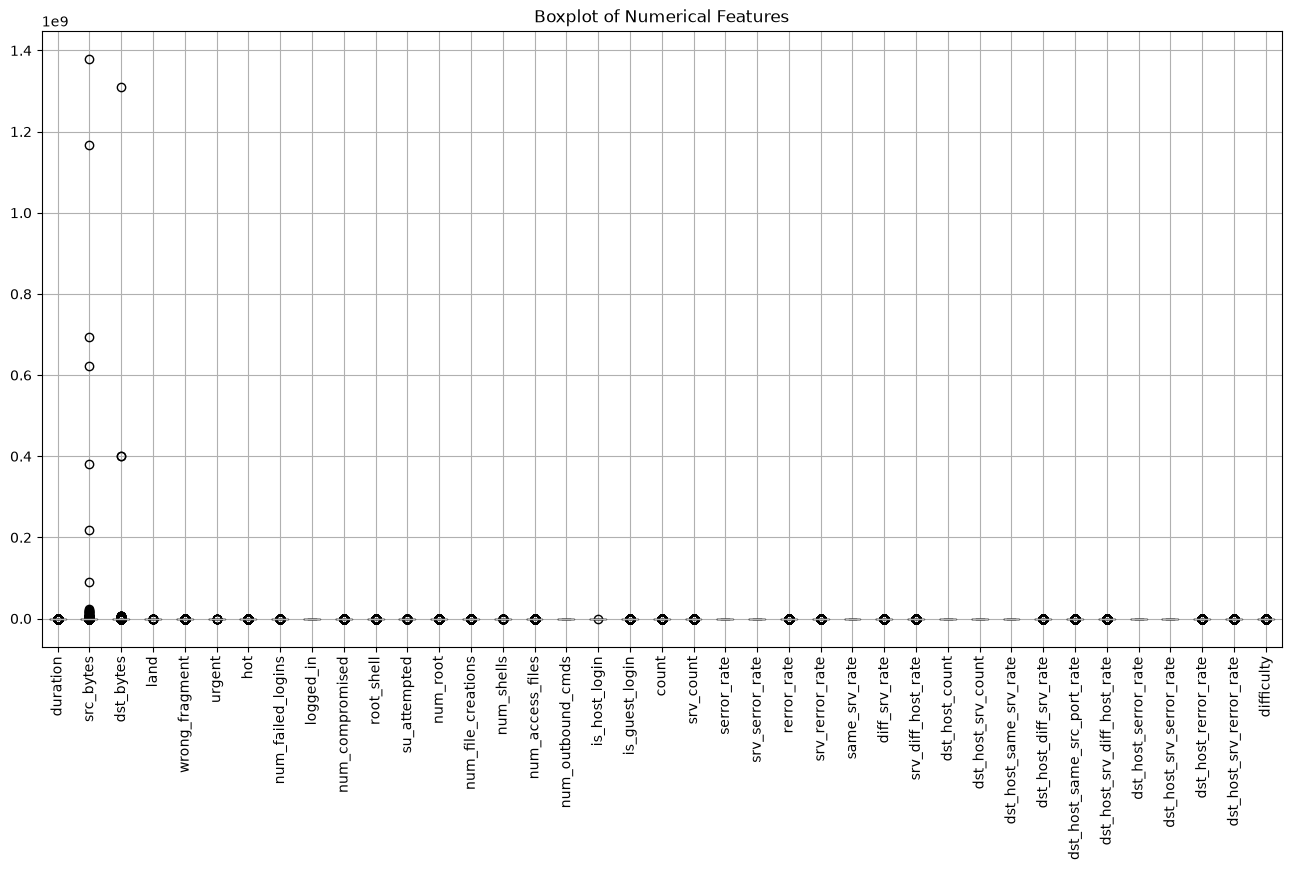

In [15]:
df.select_dtypes(include="number").boxplot(figsize=(16, 8))

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=90)
plt.show()

## Conclusion

This EDA establishes the main characteristics of the NSL-KDD training data: it contains mixed numerical and categorical network features, multiple attack classes, and a binary normal-versus-attack target. The class-count and percentage summaries show whether the target is imbalanced, while the descriptive statistics, histograms, correlations, and boxplots reveal scale differences, skewed variables, feature relationships, and potential outliers.

These findings motivate the next preparation steps: encode categorical features, scale numeric features appropriately, preserve class proportions when splitting the data, and evaluate the model with metrics that do not hide minority-class performance.